# Homework 5

Harsh Toshniwal

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import cross_val_score

## 1(a) Load the Acute Inflammations data

In [2]:
# The file is UTF-16, tab separated, and uses a comma as the decimal point (35,5)
columns = ['temperature', 'nausea', 'lumbar_pain', 'urine_pushing', 'micturition_pains',
           'burning_urethra', 'bladder', 'nephritis']

df = pd.read_csv('Homework 5 Data/diagnosis.data', encoding='utf-16', sep='\t',
                 header=None, names=columns, decimal=',')
df.head()

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder,nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


In [3]:
df.shape

(120, 8)

In [4]:
# Change yes/no to 1/0
yes_no_columns = ['nausea', 'lumbar_pain', 'urine_pushing', 'micturition_pains',
                  'burning_urethra', 'bladder', 'nephritis']

for col in yes_no_columns:
    df[col] = df[col].map({'yes': 1, 'no': 0})

df.head()

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


## 1(b) Build a decision tree on the whole data set

The data has two labels: inflammation of the urinary bladder and nephritis of renal
pelvis origin. I used the label powerset method, which combines the two labels into
one class with 4 values: none, bladder, nephritis, both.

Label powerset makes sense here. There are only 4 possible combinations, and all 4
appear in the data. One tree for both labels gives one set of rules that a doctor can
read for the full diagnosis. Binary relevance would build two separate trees and ignore
any link between the two diseases.

In [5]:
labels = []
for i in range(len(df)):
    b = df['bladder'][i]
    n = df['nephritis'][i]
    if b == 1 and n == 1:
        labels.append('both')
    elif b == 1:
        labels.append('bladder')
    elif n == 1:
        labels.append('nephritis')
    else:
        labels.append('none')

df['label'] = labels
df['label'].value_counts()

label
bladder      40
nephritis    31
none         30
both         19
Name: count, dtype: int64

In [6]:
features = ['temperature', 'nausea', 'lumbar_pain', 'urine_pushing', 'micturition_pains', 'burning_urethra']

X = df[features]
y = df['label']

tree = DecisionTreeClassifier(random_state=0)
tree.fit(X, y)

print('Number of leaves:', tree.get_n_leaves())
print('Depth:', tree.get_depth())
print('Training accuracy:', tree.score(X, y))

Number of leaves: 6
Depth: 4
Training accuracy: 1.0


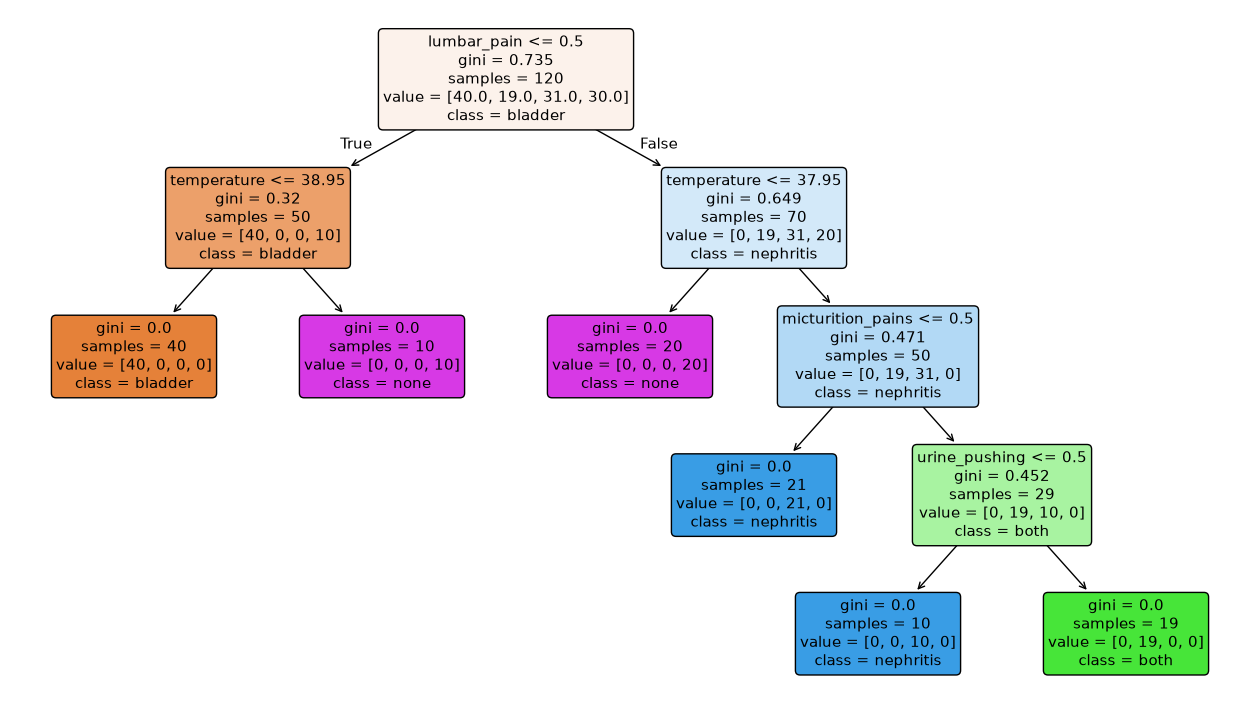

In [7]:
plt.figure(figsize=(16, 9))
plot_tree(tree, feature_names=features, class_names=tree.classes_, filled=True, rounded=True)
plt.show()

## 1(c) IF-THEN rules

The nodes in sklearn's tree are stored in order, so a parent always comes before its
children. I go through the nodes and keep the path of conditions to each node. When
I reach a leaf, the path is one rule.

In [8]:
print(export_text(tree, feature_names=features))

|--- lumbar_pain <= 0.50
|   |--- temperature <= 38.95
|   |   |--- class: bladder
|   |--- temperature >  38.95
|   |   |--- class: none
|--- lumbar_pain >  0.50
|   |--- temperature <= 37.95
|   |   |--- class: none
|   |--- temperature >  37.95
|   |   |--- micturition_pains <= 0.50
|   |   |   |--- class: nephritis
|   |   |--- micturition_pains >  0.50
|   |   |   |--- urine_pushing <= 0.50
|   |   |   |   |--- class: nephritis
|   |   |   |--- urine_pushing >  0.50
|   |   |   |   |--- class: both



In [9]:
t = tree.tree_
paths = {0: []}
rules = []

for node in range(t.node_count):
    left = t.children_left[node]
    right = t.children_right[node]

    if left == -1:
        # leaf node
        predicted = tree.classes_[np.argmax(t.value[node])]
        samples = t.n_node_samples[node]
        rules.append([paths[node], predicted, samples])
    else:
        name = features[t.feature[node]]
        if name == 'temperature':
            paths[left] = paths[node] + ['temperature <= ' + str(round(t.threshold[node], 2))]
            paths[right] = paths[node] + ['temperature > ' + str(round(t.threshold[node], 2))]
        else:
            paths[left] = paths[node] + [name + ' = no']
            paths[right] = paths[node] + [name + ' = yes']

for conditions, predicted, samples in rules:
    print('IF ' + ' AND '.join(conditions) + ' THEN ' + predicted + '   (' + str(samples) + ' samples)')

IF lumbar_pain = no AND temperature <= 38.95 THEN bladder   (40 samples)
IF lumbar_pain = no AND temperature > 38.95 THEN none   (10 samples)
IF lumbar_pain = yes AND temperature <= 37.95 THEN none   (20 samples)
IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no THEN nephritis   (21 samples)
IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no THEN nephritis   (10 samples)
IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes THEN both   (19 samples)


## 1(d) Cost-complexity pruning

In [10]:
path = tree.cost_complexity_pruning_path(X, y)
alphas = path.ccp_alphas
alphas

array([0.        , 0.09816667, 0.13333333, 0.182     , 0.22291667])

In [11]:
results = []
for a in alphas:
    pruned = DecisionTreeClassifier(random_state=0, ccp_alpha=a)
    pruned.fit(X, y)
    cv_acc = cross_val_score(DecisionTreeClassifier(random_state=0, ccp_alpha=a), X, y, cv=5).mean()
    results.append([a, pruned.get_n_leaves(), pruned.get_depth(), pruned.score(X, y), cv_acc])

results = pd.DataFrame(results, columns=['alpha', 'leaves', 'depth', 'train_accuracy', 'cv_accuracy'])
results

,alpha,leaves,depth,train_accuracy,cv_accuracy
0,0.000000,6,4,1.000000,0.958333
1,0.098167,4,2,0.841667,0.775000
2,0.133333,3,2,0.758333,0.716667
3,0.182000,2,1,0.591667,0.600000
4,0.222917,1,0,0.333333,0.433333


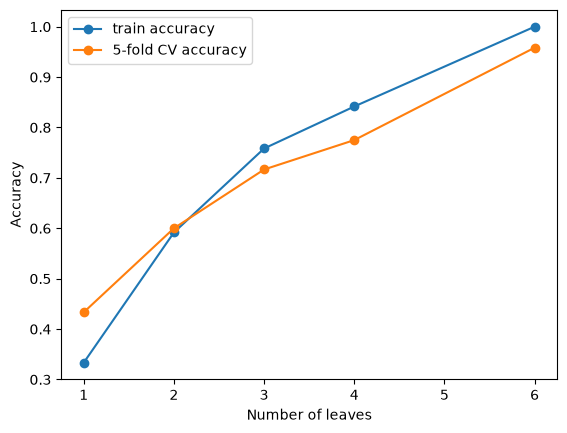

In [12]:
plt.plot(results['leaves'], results['train_accuracy'], marker='o', label='train accuracy')
plt.plot(results['leaves'], results['cv_accuracy'], marker='o', label='5-fold CV accuracy')
plt.xlabel('Number of leaves')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

Every step of pruning loses accuracy. The full tree with 6 leaves is the only one that
gets all 120 samples right, and it also has the best CV accuracy. Pruning to 4 leaves
drops training accuracy to about 84% and CV accuracy to about 78%. So the minimal tree
that still diagnoses every case correctly is the alpha = 0 tree from part (b). It is
already small, with only 4 features used and at most 4 conditions per rule.

Below I also show the 4-leaf tree, the next pruning step, to see what is lost.

Chosen alpha: 0.0


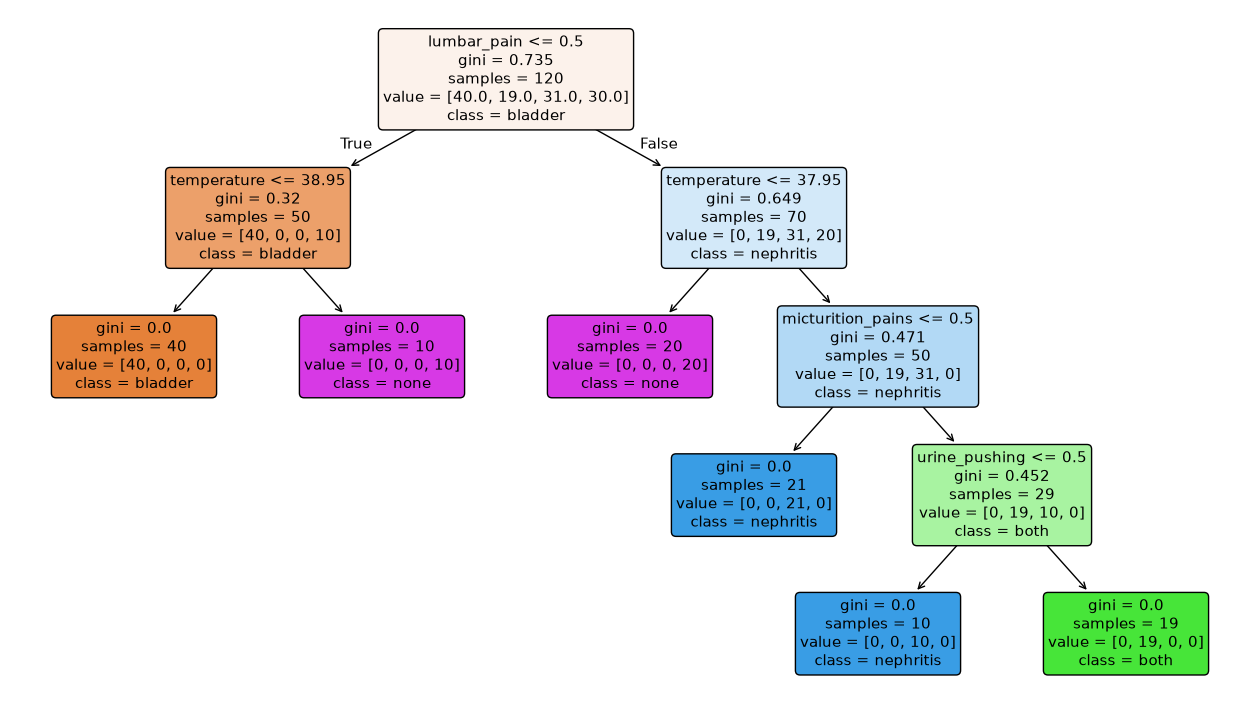

In [13]:
best_alpha = results['alpha'][results['cv_accuracy'].idxmax()]
print('Chosen alpha:', best_alpha)

final_tree = DecisionTreeClassifier(random_state=0, ccp_alpha=best_alpha)
final_tree.fit(X, y)

plt.figure(figsize=(16, 9))
plot_tree(final_tree, feature_names=features, class_names=final_tree.classes_, filled=True, rounded=True)
plt.show()

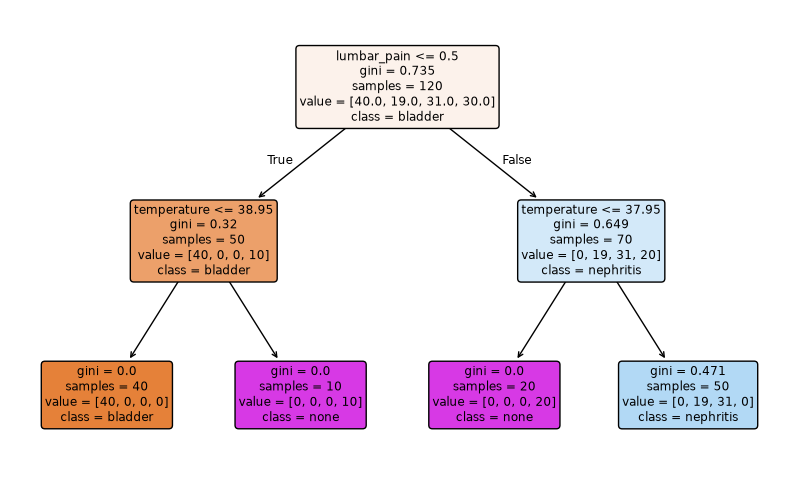

In [14]:
small_tree = DecisionTreeClassifier(random_state=0, ccp_alpha=alphas[1])
small_tree.fit(X, y)

plt.figure(figsize=(10, 6))
plot_tree(small_tree, feature_names=features, class_names=small_tree.classes_, filled=True, rounded=True)
plt.show()

In [15]:
for title, model in [['Final pruned tree (alpha = ' + str(best_alpha) + ')', final_tree],
                     ['4-leaf tree (alpha = ' + str(round(alphas[1], 4)) + ')', small_tree]]:
    print(title)
    t = model.tree_
    paths = {0: []}

    for node in range(t.node_count):
        left = t.children_left[node]
        right = t.children_right[node]

        if left == -1:
            predicted = model.classes_[np.argmax(t.value[node])]
            samples = t.n_node_samples[node]
            print('IF ' + ' AND '.join(paths[node]) + ' THEN ' + predicted + '   (' + str(samples) + ' samples)')
        else:
            name = features[t.feature[node]]
            if name == 'temperature':
                paths[left] = paths[node] + ['temperature <= ' + str(round(t.threshold[node], 2))]
                paths[right] = paths[node] + ['temperature > ' + str(round(t.threshold[node], 2))]
            else:
                paths[left] = paths[node] + [name + ' = no']
                paths[right] = paths[node] + [name + ' = yes']
    print()

Final pruned tree (alpha = 0.0)
IF lumbar_pain = no AND temperature <= 38.95 THEN bladder   (40 samples)
IF lumbar_pain = no AND temperature > 38.95 THEN none   (10 samples)
IF lumbar_pain = yes AND temperature <= 37.95 THEN none   (20 samples)
IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no THEN nephritis   (21 samples)
IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no THEN nephritis   (10 samples)
IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes THEN both   (19 samples)

4-leaf tree (alpha = 0.0982)
IF lumbar_pain = no AND temperature <= 38.95 THEN bladder   (40 samples)
IF lumbar_pain = no AND temperature > 38.95 THEN none   (10 samples)
IF lumbar_pain = yes AND temperature <= 37.95 THEN none   (20 samples)
IF lumbar_pain = yes AND temperature > 37.95 THEN nephritis   (50 samples)



# 2. The LASSO and Boosting for Regression

In [16]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

## 2(a) Load the Communities and Crime data

The column names are in the `@attribute` lines of `communities.names`. Missing values are marked with `?`.

In [17]:
names = []
with open('Homework 5 Data/communities.names') as f:
    for line in f:
        if line.startswith('@attribute'):
            names.append(line.split()[1])

len(names)

128

In [18]:
crime = pd.read_csv('Homework 5 Data/communities.data', header=None, names=names, na_values='?')
crime.head()

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


In [19]:
crime.shape

(1994, 128)

## 2(b) Remove non-predictive features and impute missing values

The data description says state, county, community, communityname and fold are not predictive.

In [20]:
crime = crime.drop(columns=['state', 'county', 'community', 'communityname', 'fold'])
crime.shape

(1994, 123)

In [21]:
missing = crime.isna().sum()
missing[missing > 0]

OtherPerCap                1
LemasSwornFT            1675
LemasSwFTPerPop         1675
LemasSwFTFieldOps       1675
LemasSwFTFieldPerPop    1675
LemasTotalReq           1675
LemasTotReqPerPop       1675
PolicReqPerOffic        1675
PolicPerPop             1675
RacialMatchCommPol      1675
PctPolicWhite           1675
PctPolicBlack           1675
PctPolicHisp            1675
PctPolicAsian           1675
PctPolicMinor           1675
OfficAssgnDrugUnits     1675
NumKindsDrugsSeiz       1675
PolicAveOTWorked        1675
PolicCars               1675
PolicOperBudg           1675
LemasPctPolicOnPatr     1675
LemasGangUnitDeploy     1675
PolicBudgPerPop         1675
dtype: int64

In [22]:
train = crime.iloc[:1495]
test = crime.iloc[1495:]

print(train.shape, test.shape)

(1495, 123) (499, 123)


OtherPerCap has 1 missing value. The 22 police columns are missing for 1675 of the 1994
rows. I used median imputation and computed the medians from the training set only, so
the test set does not leak into training.

In [23]:
imputer = SimpleImputer(strategy='median')
imputer.fit(train)

train = pd.DataFrame(imputer.transform(train), columns=crime.columns)
test = pd.DataFrame(imputer.transform(test), columns=crime.columns)

print(train.isna().sum().sum(), test.isna().sum().sum())

0 0


In [24]:
X_train = train.drop(columns=['ViolentCrimesPerPop'])
y_train = train['ViolentCrimesPerPop']
X_test = test.drop(columns=['ViolentCrimesPerPop'])
y_test = test['ViolentCrimesPerPop']

print(X_train.shape, X_test.shape)

(1495, 122) (499, 122)


## 2(c) Correlation matrix

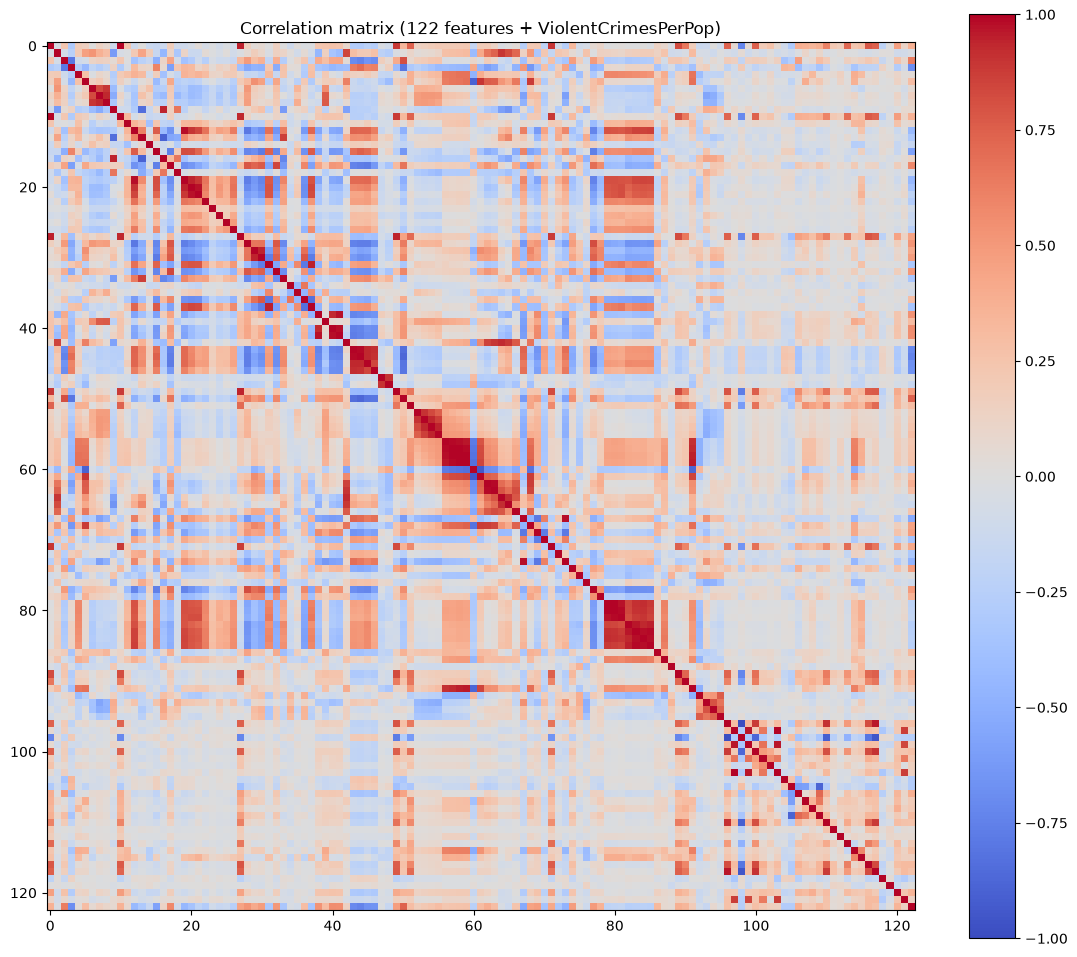

In [25]:
all_data = pd.concat([train, test])
corr = all_data.corr()

plt.figure(figsize=(14, 12))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.title('Correlation matrix (122 features + ViolentCrimesPerPop)')
plt.show()

In [26]:
# Features most correlated with the target
corr['ViolentCrimesPerPop'].drop('ViolentCrimesPerPop').sort_values(ascending=False)

PctIlleg            0.737957
racepctblack        0.631264
pctWPubAsst         0.574665
FemalePctDiv        0.556032
TotalPctDiv         0.552777
                      ...   
PctTeen2Par        -0.661582
PctYoungKids2Par   -0.666059
racePctWhite       -0.684770
PctFam2Par         -0.706667
PctKids2Par        -0.738424
Name: ViolentCrimesPerPop, Length: 122, dtype: float64

## 2(d) Coefficient of Variation

In [27]:
features_all = all_data.drop(columns=['ViolentCrimesPerPop'])

cv_values = features_all.std() / features_all.mean()
cv_values = cv_values.sort_values(ascending=False)
cv_values

PctPolicAsian          5.447835
NumStreet              4.407702
NumInShelters          3.485481
NumIlleg               2.994196
NumImmig               2.900497
                         ...   
NumKindsDrugsSeiz      0.143227
RacialMatchCommPol     0.126902
LemasPctPolicOnPatr    0.117807
PctPolicWhite          0.117726
LemasSwFTFieldOps      0.057515
Length: 122, dtype: float64

## 2(e) Top floor(sqrt(128)) = 11 features by CV

In [28]:
top_features = list(cv_values.index[:11])
top_features

['PctPolicAsian',
 'NumStreet',
 'NumInShelters',
 'NumIlleg',
 'NumImmig',
 'LemasPctOfficDrugUn',
 'NumUnderPov',
 'population',
 'LemasSwornFT',
 'numbUrban',
 'HousVacant']

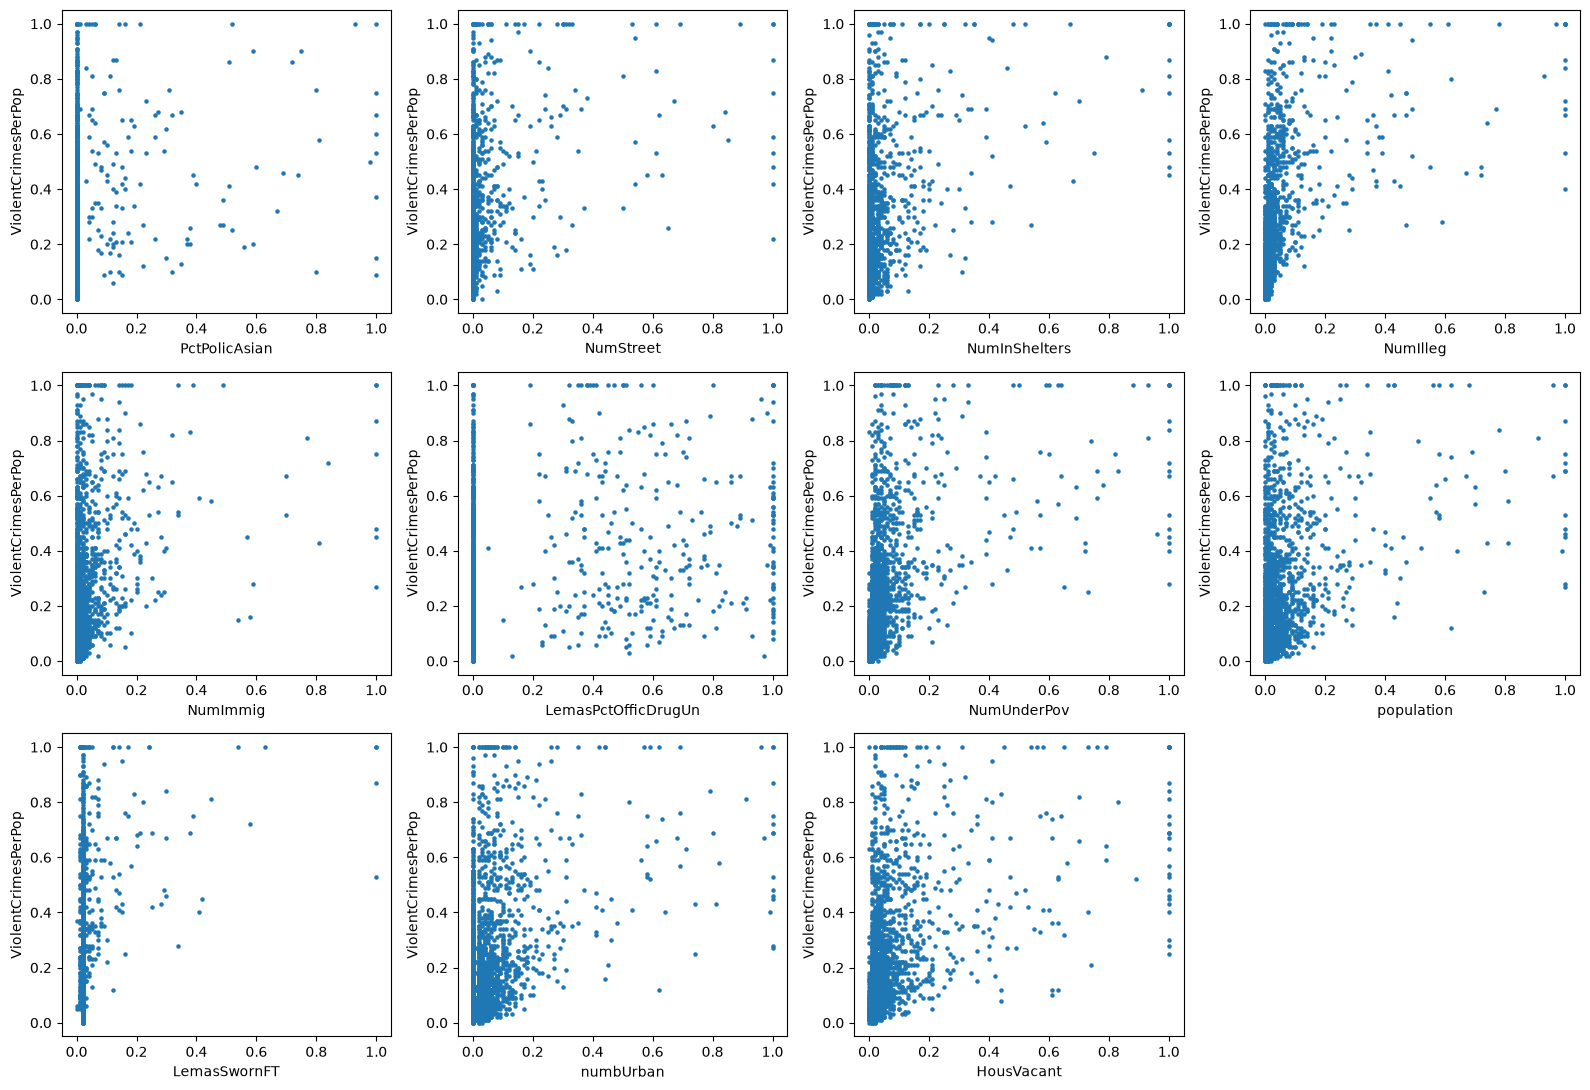

In [29]:
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes = axes.flatten()

for i in range(11):
    axes[i].scatter(all_data[top_features[i]], all_data['ViolentCrimesPerPop'], s=5)
    axes[i].set_xlabel(top_features[i])
    axes[i].set_ylabel('ViolentCrimesPerPop')

axes[11].axis('off')
plt.tight_layout()
plt.show()

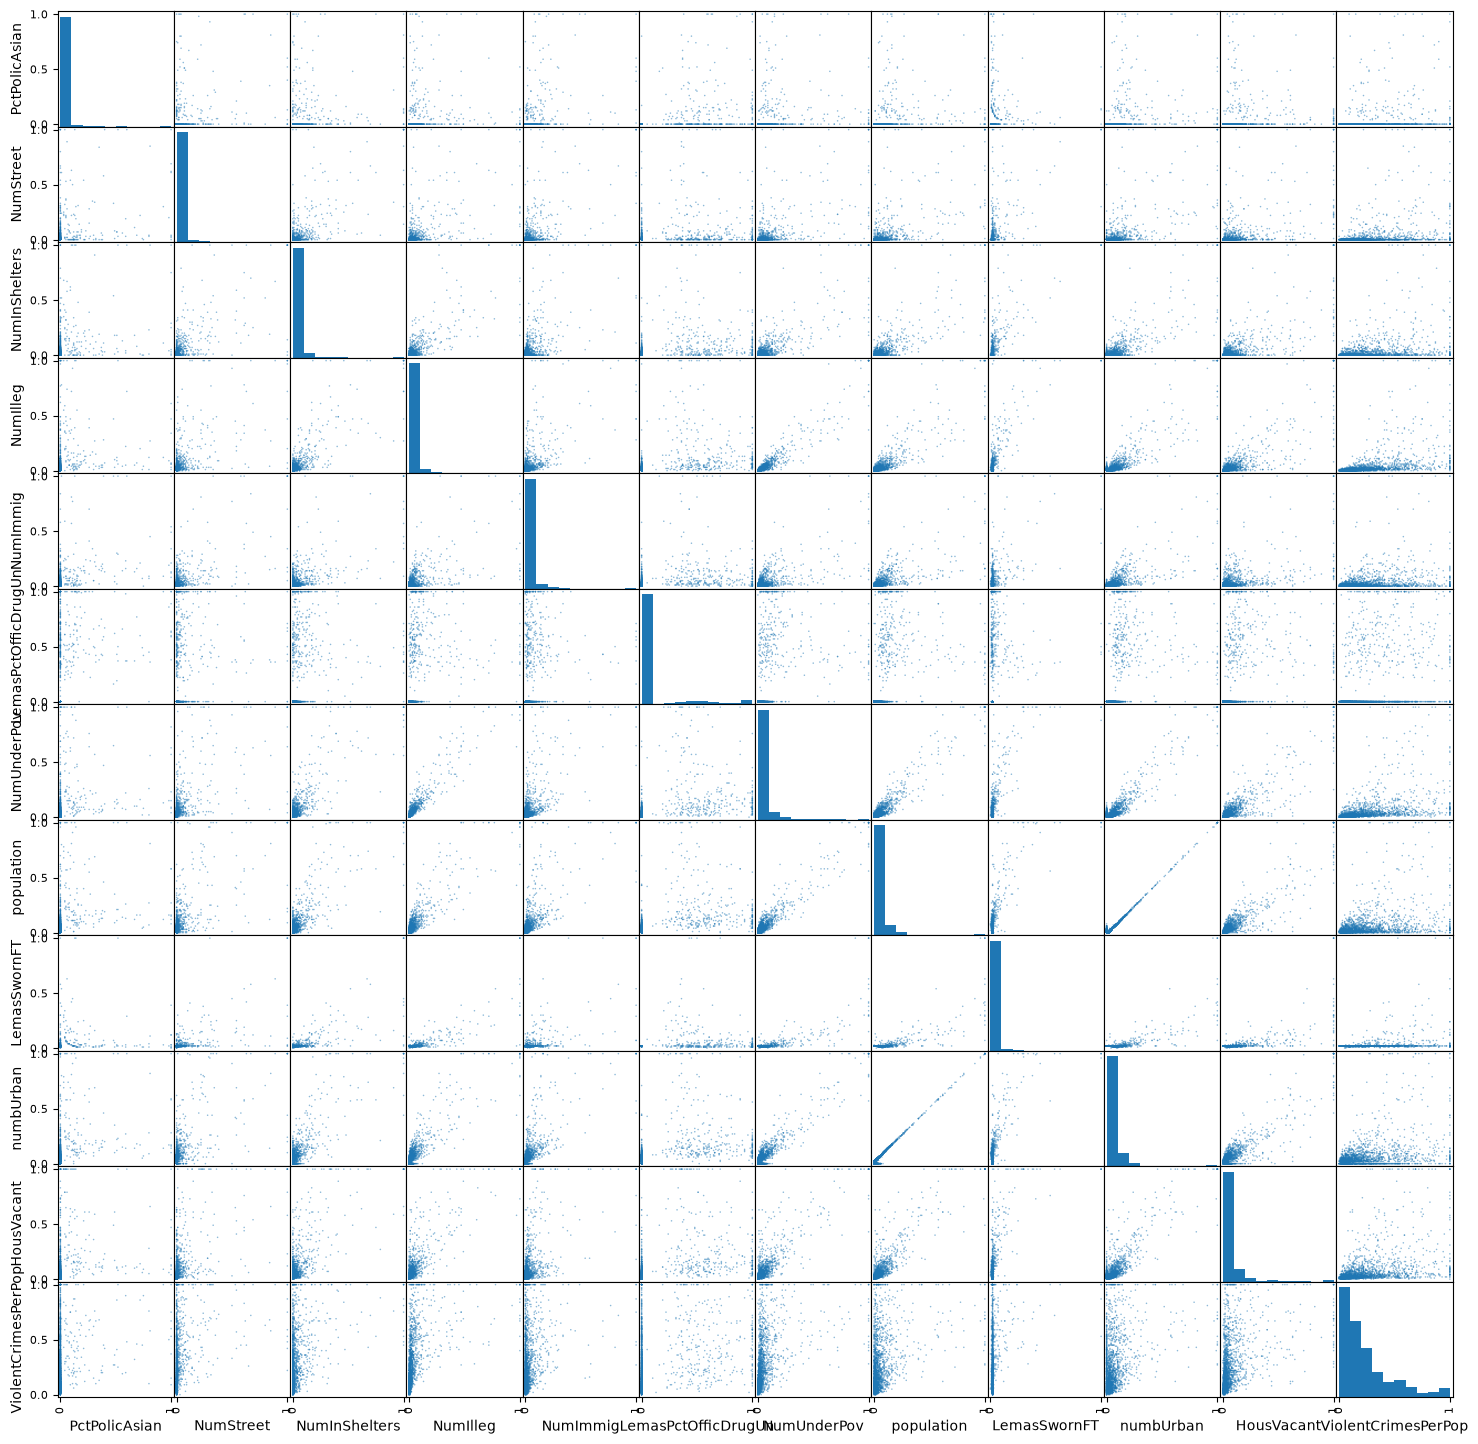

In [30]:
pd.plotting.scatter_matrix(all_data[top_features + ['ViolentCrimesPerPop']], figsize=(18, 18), s=5)
plt.show()

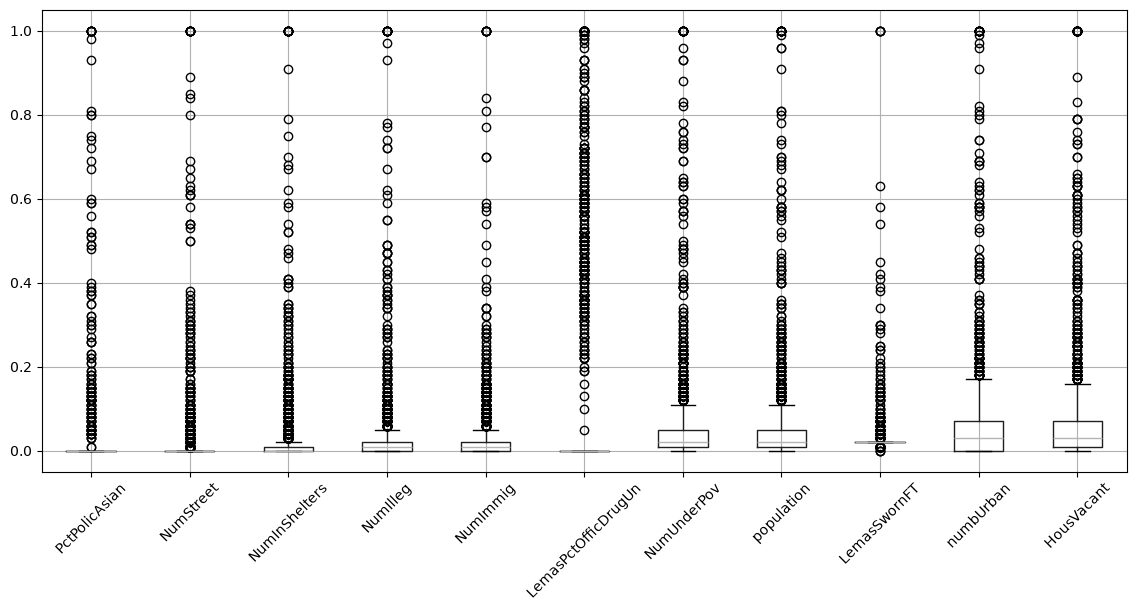

In [31]:
plt.figure(figsize=(14, 6))
all_data[top_features].boxplot()
plt.xticks(rotation=45)
plt.show()

No, we cannot draw conclusions about significance from these scatter plots alone. Most of these
features are count variables (NumStreet, NumIlleg, NumImmig, population, NumUnderPov, ...), so almost all
points are piled up near 0 with a few large cities spread out to the right. The box plots show the same
thing: the boxes are squeezed near 0 and most of the range is outliers. Some plots show a loose upward
trend (NumIlleg, NumUnderPov), but the spread of crime rates is very wide at every value. A scatter plot
only shows one feature at a time, and these features are strongly correlated with each other (they all
grow with city size), so whether a feature is significant has to be tested in a model, for example with
t-tests on the regression coefficients. Two of the features (PctPolicAsian, LemasPctOfficDrugUn) are
police columns that were mostly missing, so their high CV is partly caused by the imputation: most rows
got the same median value, which shows up as the vertical line at 0.

## 2(f) Linear model with least squares

The test error is the mean squared error on the test set.

In [32]:
ols = LinearRegression()
ols.fit(X_train, y_train)

ols_mse = mean_squared_error(y_test, ols.predict(X_test))
print('Least squares test MSE:', ols_mse)

Least squares test MSE: 0.017966215426067335


## 2(g) Ridge regression with lambda chosen by cross-validation

In [33]:
lambdas = np.logspace(-3, 3, 100)

ridge = RidgeCV(alphas=lambdas, cv=10)
ridge.fit(X_train, y_train)

ridge_mse = mean_squared_error(y_test, ridge.predict(X_test))
print('Best lambda:', ridge.alpha_)
print('Ridge test MSE:', ridge_mse)

Best lambda: 2.1544346900318843
Ridge test MSE: 0.017525046262751982


## 2(h) LASSO with lambda chosen by cross-validation

In [34]:
lasso = LassoCV(cv=10, random_state=0, max_iter=10000)
lasso.fit(X_train, y_train)

lasso_mse = mean_squared_error(y_test, lasso.predict(X_test))
print('Best lambda:', lasso.alpha_)
print('LASSO test MSE:', lasso_mse)

Best lambda: 0.00010831930127505137
LASSO test MSE: 0.01764645368328724


In [35]:
selected = []
for i in range(len(X_train.columns)):
    if lasso.coef_[i] != 0:
        selected.append(X_train.columns[i])

print(len(selected), 'variables selected:')
print(selected)

73 variables selected:
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctBSorMore', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBorn', 'PctSameCity85', 'LemasSwFTFieldPer

### LASSO with standardized features

In [36]:
scaler = StandardScaler()
scaler.fit(X_train)

X_train_std = scaler.transform(X_train)
X_test_std = scaler.transform(X_test)

lasso_std = LassoCV(cv=10, random_state=0, max_iter=10000)
lasso_std.fit(X_train_std, y_train)

lasso_std_mse = mean_squared_error(y_test, lasso_std.predict(X_test_std))
print('Best lambda:', lasso_std.alpha_)
print('LASSO (standardized) test MSE:', lasso_std_mse)

Best lambda: 0.0006636910154760816
LASSO (standardized) test MSE: 0.01771233241520385


In [37]:
selected_std = []
for i in range(len(X_train.columns)):
    if lasso_std.coef_[i] != 0:
        selected_std.append(X_train.columns[i])

print(len(selected_std), 'variables selected:')
print(selected_std)

75 variables selected:
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBorn', 'PctSameCity85', 'LemasSwFTField

In [38]:
print('LASSO test MSE (original):    ', lasso_mse)
print('LASSO test MSE (standardized):', lasso_std_mse)

LASSO test MSE (original):     0.01764645368328724
LASSO test MSE (standardized): 0.01771233241520385


The two LASSO models are almost the same: test MSE 0.01765 with the original features and 0.01771
with standardized features. Both LASSO models are slightly better than least squares (0.01797) and close to ridge (0.01753).

## 2(i) PCR with M chosen by cross-validation

In [39]:
kfold = KFold(n_splits=10, shuffle=True, random_state=0)

pcr_cv_mse = []
for m in range(1, X_train.shape[1] + 1):
    pcr = make_pipeline(PCA(n_components=m), LinearRegression())
    scores = cross_val_score(pcr, X_train, y_train, cv=kfold, scoring='neg_mean_squared_error')
    pcr_cv_mse.append(-scores.mean())

best_m = np.argmin(pcr_cv_mse) + 1
print('Best M:', best_m)

Best M: 95


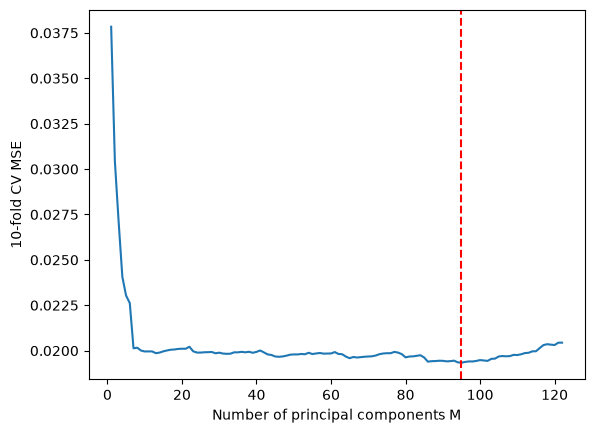

In [40]:
plt.plot(range(1, X_train.shape[1] + 1), pcr_cv_mse)
plt.axvline(best_m, color='red', linestyle='--')
plt.xlabel('Number of principal components M')
plt.ylabel('10-fold CV MSE')
plt.show()

In [41]:
pcr = make_pipeline(PCA(n_components=best_m), LinearRegression())
pcr.fit(X_train, y_train)

pcr_mse = mean_squared_error(y_test, pcr.predict(X_test))
print('PCR test MSE:', pcr_mse)

PCR test MSE: 0.018374001520908012


## 2(j) L1-penalized gradient boosting tree with XGBoost

`reg_alpha` in XGBoost is the L1 penalty on the leaf weights. I chose it with 10-fold
cross-validation and kept the other settings fixed.

In [42]:
xgb = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=0)

param_grid = {'reg_alpha': [0, 0.001, 0.01, 0.1, 0.5, 1, 2, 5, 10]}

grid = GridSearchCV(xgb, param_grid, cv=10, scoring='neg_mean_squared_error')
grid.fit(X_train, y_train)

print('Best alpha:', grid.best_params_['reg_alpha'])

Best alpha: 0.5


In [43]:
pd.DataFrame({'alpha': param_grid['reg_alpha'], 'cv_mse': -grid.cv_results_['mean_test_score']})

,alpha,cv_mse
0,0.000,0.020195
1,0.001,0.020151
2,0.010,0.020019
3,0.100,0.020073
4,0.500,0.019682
5,1.000,0.019732
6,2.000,0.020010
7,5.000,0.020156
8,10.000,0.021434


In [44]:
xgb_mse = mean_squared_error(y_test, grid.predict(X_test))
print('XGBoost test MSE:', xgb_mse)

XGBoost test MSE: 0.016682024064232838


### Summary of test errors

In [45]:
print('Least squares:      ', ols_mse)
print('Ridge:              ', ridge_mse)
print('LASSO:              ', lasso_mse)
print('LASSO standardized: ', lasso_std_mse)
print('PCR:                ', pcr_mse)
print('XGBoost:            ', xgb_mse)

Least squares:       0.017966215426067335
Ridge:               0.017525046262751982
LASSO:               0.01764645368328724
LASSO standardized:  0.01771233241520385
PCR:                 0.018374001520908012
XGBoost:             0.016682024064232838
